In [1]:
## Bibliotecas
import requests
import unicodedata
import geopandas as gpd
from shapely.geometry import Polygon
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box
from tqdm import tqdm
import matplotlib.colors as mcolors
import numpy as np
from tqdm import tqdm
from shapely.geometry import Point
import folium
from folium import Choropleth, Circle, Marker
from folium.plugins import HeatMap, MarkerCluster
import branca.colormap as cm

In [2]:
# Biblioteca propia
from creador_poligonos import extractor_poligonos_localidades,subdivide_polygon_with_names

In [3]:
poligono_bolivar=extractor_poligonos_localidades('Ciudad Bolívar')
poligono_sancristobal =extractor_poligonos_localidades('San Cristóbal')
# Crear las subdivisiones y los nombres de bloques para Ciudad Bolívar y San Cristóbal
print("Generando sub-polígonos y nombres para Ciudad Bolívar...")
bolivar_subpolygons, bolivar_block_names = subdivide_polygon_with_names(poligono_bolivar, 'Ciudad Bolívar', cell_size=100)
print("Generando sub-polígonos y nombres para San Cristóbal...")
sancristobal_subpolygons, sancristobal_block_names = subdivide_polygon_with_names(poligono_sancristobal, 'San Cristóbal', cell_size=100)

Generando sub-polígonos y nombres para Ciudad Bolívar...


Procesando Ciudad Bolívar eje X: 100%|██████████| 103/103 [00:23<00:00,  4.30it/s]


Generando sub-polígonos y nombres para San Cristóbal...


Procesando San Cristóbal eje X: 100%|██████████| 87/87 [00:06<00:00, 13.57it/s]


In [4]:
# Crear un nuevo GeoDataFrame con las subdivisiones y los nombres de bloques
localidades = ['Ciudad Bolívar'] * len(bolivar_subpolygons) + ['San Cristóbal'] * len(sancristobal_subpolygons)
block_names = bolivar_block_names + sancristobal_block_names

gdf_subpolygons = gpd.GeoDataFrame({
    'Localidad': localidades,
    'Bloque': block_names,
    'geometry': bolivar_subpolygons + sancristobal_subpolygons
}, crs="EPSG:3116")  # Mantener la proyección en metros
# Coordinates of the TransMiCable stations (Simon Bolívar area)
transmicable_stations = {
    "Portal del Tunal": (4.568874258616699, -74.13946745553427),
    "Juan Pablo II": (4.555992907670105, -74.14740979258688),
    "Manitas": (4.5505494740333985, -74.15058826560421),
    "Mirador del Paraíso": (4.5502151330274065, -74.15891333669026)
}

# Convert the station coordinates to a GeoDataFrame
station_points = [Point(lon, lat) for lat, lon in transmicable_stations.values()]
gdf_stations = gpd.GeoDataFrame({
    'Station': transmicable_stations.keys(),
    'geometry': station_points
}, crs="EPSG:4326")

# Reproject both the block and station GeoDataFrames to EPSG:3116 (for distance in meters)
gdf_subpolygons = gdf_subpolygons.to_crs(epsg=3116)
gdf_stations = gdf_stations.to_crs(epsg=3116)

# Function to calculate the minimum distance from each block to the nearest station
def calculate_min_distance(block, stations):
    return stations.geometry.apply(lambda station: block.geometry.distance(station)).min()

# Apply the distance calculation to each block
gdf_subpolygons['min_distance_to_station'] = gdf_subpolygons.apply(
    calculate_min_distance, stations=gdf_stations, axis=1
)

In [7]:
gdf=gdf_subpolygons

C:\Users\juane\AppData\Local\Temp\ipykernel_39700\3718913855.py:13: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend()
C:\Users\juane\AppData\Local\Temp\ipykernel_39700\3718913855.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


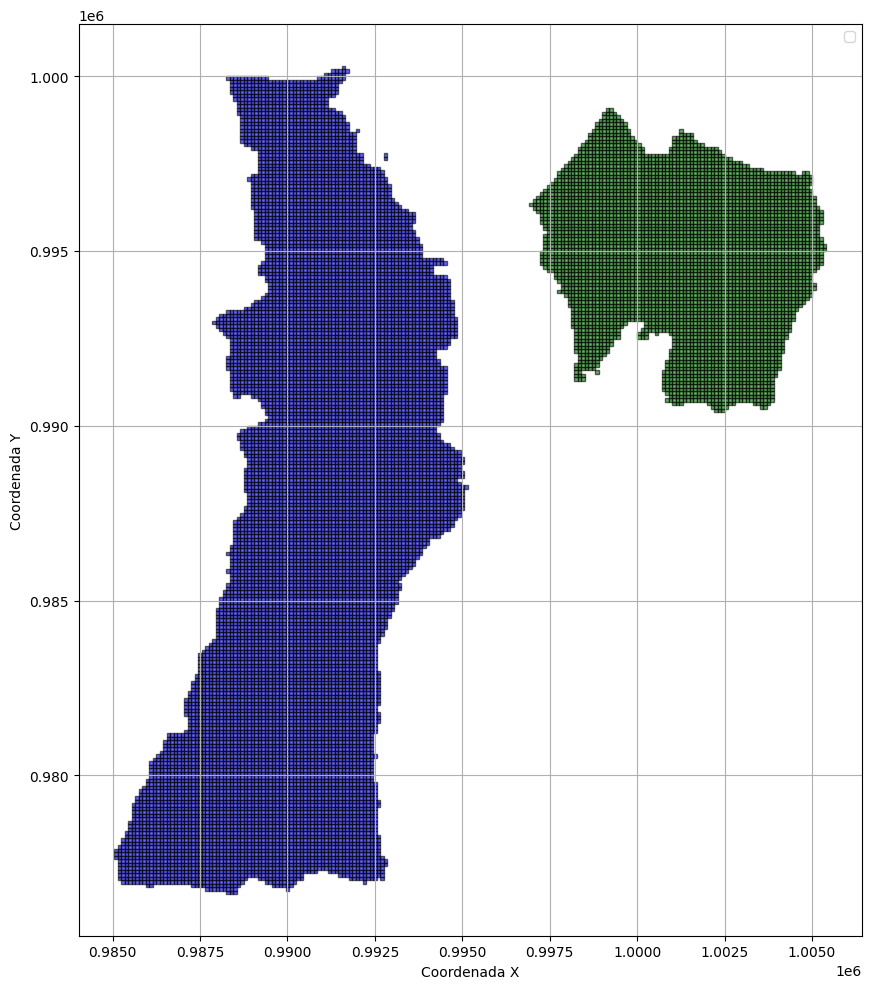

In [9]:
# Separar por localidades
ciudad_bolivar = gdf[gdf["Localidad"] == "Ciudad Bolívar"]
san_cristobal = gdf[gdf["Localidad"] == "San Cristóbal"]

# Crear el plot
fig, ax = plt.subplots(figsize=(10, 10))

# Plotear cada conjunto de polígonos con colores diferentes
ciudad_bolivar.plot(ax=ax, color="blue", edgecolor="black", alpha=0.6, label="Ciudad Bolívar")
san_cristobal.plot(ax=ax, color="green", edgecolor="black", alpha=0.6, label="San Cristóbal")

# Añadir leyenda y mejorar la apariencia
plt.legend()
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.grid(True)

# Ajustar para mejor visualización
plt.tight_layout()

# Mostrar la gráfica
plt.show()

In [29]:
# Función para dividir el polígono en bloques de 20x20 metros, asegurando que los sub-polígonos estén dentro del polígono original
def subdivide_polygon_with_names(polygon, localidad_name, cell_size=50):
    minx, miny, maxx, maxy = polygon.bounds
    x_coords = np.arange(minx, maxx, cell_size)
    y_coords = np.arange(miny, maxy, cell_size)
    
    sub_polygons = []
    block_names = []
    block_counter = 1
    
    for x in tqdm(x_coords, desc=f'Procesando {localidad_name} eje X'):
        for y in tqdm(y_coords, desc=f'Procesando {localidad_name} eje Y', leave=False):
            # Crear un sub-polígono de 20x20 metros
            sub_polygon = box(x, y, x + cell_size, y + cell_size)
            # Verificar si el sub-polígono está completamente dentro del polígono original
            if polygon.contains(sub_polygon):
                sub_polygons.append(sub_polygon)
                # Crear el nombre del bloque
                block_name = f"{localidad_name}_bloque_{block_counter}_{cell_size}_x_{cell_size}"
                block_names.append(block_name)
                block_counter += 1
    
    return sub_polygons, block_names

In [ ]:

# Crear las subdivisiones y los nombres de bloques para Ciudad Bolívar y San Cristóbal
print("Generando sub-polígonos y nombres para Ciudad Bolívar...")
bolivar_subpolygons, bolivar_block_names = subdivide_polygon_with_names(gdf.geometry.iloc[0], 'simon_bolivar', cell_size=100)

print("Generando sub-polígonos y nombres para San Cristóbal...")
sancristobal_subpolygons, sancristobal_block_names = subdivide_polygon_with_names(gdf.geometry.iloc[1], 'san_cristobal', cell_size=100)

# Crear un nuevo GeoDataFrame con las subdivisiones y los nombres de bloques
localidades = ['Ciudad Bolívar'] * len(bolivar_subpolygons) + ['San Cristóbal'] * len(sancristobal_subpolygons)
block_names = bolivar_block_names + sancristobal_block_names

gdf_subpolygons = gpd.GeoDataFrame({
    'Localidad': localidades,
    'Bloque': block_names,
    'geometry': bolivar_subpolygons + sancristobal_subpolygons
}, crs="EPSG:3116")  # Mantener la proyección en metros

In [ ]:
gdf_subpolygons

In [8]:
# Coordinates of the TransMiCable stations (Simon Bolívar area)
transmicable_stations = {
    "Portal del Tunal": (4.568874258616699, -74.13946745553427),
    "Juan Pablo II": (4.555992907670105, -74.14740979258688),
    "Manitas": (4.5505494740333985, -74.15058826560421),
    "Mirador del Paraíso": (4.5502151330274065, -74.15891333669026)
}

# Convert the station coordinates to a GeoDataFrame
station_points = [Point(lon, lat) for lat, lon in transmicable_stations.values()]
gdf_stations = gpd.GeoDataFrame({
    'Station': transmicable_stations.keys(),
    'geometry': station_points
}, crs="EPSG:4326")

# Reproject both the block and station GeoDataFrames to EPSG:3116 (for distance in meters)
gdf_subpolygons = gdf_subpolygons.to_crs(epsg=3116)
gdf_stations = gdf_stations.to_crs(epsg=3116)

# Function to calculate the minimum distance from each block to the nearest station
def calculate_min_distance(block, stations):
    return stations.geometry.apply(lambda station: block.geometry.distance(station)).min()

# Apply the distance calculation to each block
gdf_subpolygons['min_distance_to_station'] = gdf_subpolygons.apply(
    calculate_min_distance, stations=gdf_stations, axis=1
)

In [ ]:
# Función para crear el mapa con los polígonos coloreados y borde en líneas punteadas
def plot_polygons_folium(gdf, center=[4.60971, -74.08175]):
    # Convertir a EPSG:4326 que es el sistema de coordenadas utilizado por folium
    gdf = gdf.to_crs(epsg=4326)
    
    # Crear el mapa centrado en Bogotá
    m = folium.Map(location=center, zoom_start=12)
    
    # Crear una paleta de colores para las localidades
    colormap = cm.StepColormap(['lightgreen', 'lightblue'], vmin=0, vmax=len(gdf['Localidad'].unique()))
    
    # Función para asignar colores según la localidad
    def get_color(localidad):
        if localidad == "Ciudad Bolívar":
            return 'lightblue'
        elif localidad == "San Cristóbal":
            return 'lightgreen'
        else:
            return 'gray'
    
    # Recorrer cada polígono en el GeoDataFrame
    for _, row in tqdm(gdf.iterrows()):
        # Obtener el color según la localidad
        color = get_color(row['Localidad'])
        
        # Convertir el polígono a GeoJSON y agregarlo al mapa con un estilo específico
        geo_json = folium.GeoJson(
            row['geometry'],
            style_function=lambda feature, color=color: {
                'fillColor': color,
                'color': 'black',  # Bordes en negro
                'weight': 1,       # Grosor del borde
                'fillOpacity': 0.6,
                'dashArray': '5, 5'  # Líneas punteadas: 5px línea, 5px espacio
            }
        )
        
        # Agregar cada GeoJSON al mapa
        geo_json.add_to(m)
    
    return m

# Suponiendo que gdf_subpolygons ya tiene los sub-polígonos de Ciudad Bolívar y San Cristóbal
# Dibujar los polígonos en el mapa interactivo de Bogotá con bordes punteados
m = plot_polygons_folium(gdf_subpolygons)

# Mostrar el mapa
m


In [ ]:
# Adding the TransMiCable stations to the map
transmicable_stations = {
    "Portal del Tunal": (4.568874258616699, -74.13946745553427),
    "Juan Pablo II": (4.555992907670105, -74.14740979258688),
    "Manitas": (4.5505494740333985, -74.15058826560421),
    "Mirador del Paraíso": (4.5502151330274065, -74.15891333669026)
}


# Function to plot the TransMiCable stations and connect them with red lines
def add_transmicable_with_lines(m, stations):
    station_names = list(stations.keys())
    station_coords = list(stations.values())
    
    # Add markers for the stations
    for i, (name, coords) in enumerate(stations.items()):
        folium.Marker(
            location=coords,
            popup=f"{name} (Inaugurated: 2018)",
            icon=folium.Icon(color='red', icon='info-sign')
        ).add_to(m)
    
    # Connect the stations with red lines
    folium.PolyLine(station_coords, color='red', weight=5, opacity=0.8).add_to(m)


# Add the stations and lines
add_transmicable_with_lines(m, transmicable_stations)
m

In [16]:
gdf_ciudad_bolivar=gdf_subpolygons[gdf_subpolygons['Localidad']=='Ciudad Bolívar']

In [17]:
# Function to assign color based on distance
def assign_color(distance):
    if distance <= 1000:
        return 'treated'  # treated group (Tomato Red)
    elif 1000 < distance <= 2000:
        return 'spillovers'  # spillovers (Gold)
    else:
        return 'not_treated'  # not treated (Light Sky Blue)

In [ ]:
gdf_ciudad_bolivar['clase']=gdf_ciudad_bolivar.loc[:,'min_distance_to_station'].apply(lambda x: assign_color(x))

In [ ]:
# Función para crear el mapa con los polígonos coloreados y borde en líneas punteadas
def plot_polygons_folium(gdf, center=[4.60971, -74.08175]):
    # Convertir a EPSG:4326 que es el sistema de coordenadas utilizado por folium
    gdf = gdf.to_crs(epsg=4326)
    
    # Crear el mapa centrado en Bogotá
    m = folium.Map(location=center, zoom_start=12)
    
    # Crear una paleta de colores para las localidades
    colormap = cm.StepColormap(['lightgreen', 'red','lightblue'], vmin=0, vmax=len(gdf['clase'].unique()))
    
    # Función para asignar colores según la localidad
    def get_color(clase):
        if clase == 'treated':
            return 'lightblue'
        elif clase == 'spillovers':
            return 'red'
        else:
            return 'lightgreen'
    
    # Recorrer cada polígono en el GeoDataFrame
    for _, row in tqdm(gdf.iterrows()):
        # Obtener el color según la localidad
        color = get_color(row['clase'])
        
        # Convertir el polígono a GeoJSON y agregarlo al mapa con un estilo específico
        geo_json = folium.GeoJson(
            row['geometry'],
            style_function=lambda feature, color=color: {
                'fillColor': color,
                'color': 'black',  # Bordes en negro
                'weight': 1,       # Grosor del borde
                'fillOpacity': 0.6,
                'dashArray': '5, 5'  # Líneas punteadas: 5px línea, 5px espacio
            }
        )
        
        # Agregar cada GeoJSON al mapa
        geo_json.add_to(m)
    
    return m

# Suponiendo que gdf_subpolygons ya tiene los sub-polígonos de Ciudad Bolívar y San Cristóbal
# Dibujar los polígonos en el mapa interactivo de Bogotá con bordes punteados
m = plot_polygons_folium(gdf_ciudad_bolivar)

# Mostrar el mapa
m


In [ ]:
# Adding the TransMiCable stations to the map
transmicable_stations = {
    "Portal del Tunal": (4.568874258616699, -74.13946745553427),
    "Juan Pablo II": (4.555992907670105, -74.14740979258688),
    "Manitas": (4.5505494740333985, -74.15058826560421),
    "Mirador del Paraíso": (4.5502151330274065, -74.15891333669026)
}


# Function to plot the TransMiCable stations and connect them with red lines
def add_transmicable_with_lines(m, stations):
    station_names = list(stations.keys())
    station_coords = list(stations.values())
    
    # Add markers for the stations
    for i, (name, coords) in enumerate(stations.items()):
        folium.Marker(
            location=coords,
            popup=f"{name} (Inaugurated: 2018)",
            icon=folium.Icon(color='red', icon='info-sign')
        ).add_to(m)
    
    # Connect the stations with red lines
    folium.PolyLine(station_coords, color='red', weight=5, opacity=0.8).add_to(m)


# Add the stations and lines
add_transmicable_with_lines(m, transmicable_stations)
m